# F-JEPA sur 4 ans de capteurs SYNTHÉTIQUES (4 machines)

> ⚠️ **Données inventées** (voir `generation_capteurs_4ans.ipynb` et `input/capteurs_4ans/LISEZMOI_SYNTHETIQUE.md`). Ce notebook teste si un JEPA apprend une dynamique normale assez fine pour repérer des dégradations **qui ne se voient pas dans le niveau des capteurs**. Le générateur a été conçu pour ça : un bon résultat ici montre que la démarche fonctionne quand le signal est de cette nature, **pas** qu'elle fonctionnera sur les machines réelles.

**Question posée toutes les 2 heures, pour chaque machine :** *« une panne ou un ralentissement va-t-il survenir dans les 7 prochains jours ? »*, à partir des **24 dernières heures** de capteurs (7 voies à la minute).

**Découpage chronologique** (les 4 machines ensemble) :
- entraînement : sept. 2022 → août 2024 (pré-entraînement JEPA **sans étiquettes**, puis apprentissage des têtes supervisées) ;
- validation : sept. 2024 → août 2025 (choix des hyperparamètres et des seuils d'alerte) ;
- test : sept. 2025 → août 2026 (jamais vu avant l'évaluation finale).

**Méthodes comparées**
| Famille | Méthode | Étiquettes ? |
|---|---|---|
| Seuils | niveau moyen 24 h, max des \|z\| sur les capteurs | non |
| Seuils | EWMA 3 jours des niveaux | non |
| Physique | résidus d'un modèle « sain » (capteur ~ vitesse, historique de charge, ambiante), écart-type des résidus | non |
| Supervisé | boosting sur ~100 caractéristiques expertes (niveaux, résidus, autocorrélations, corrélations croisées) | oui |
| JEPA | score de surprise (erreur de prédiction dans l'espace latent) | non |
| JEPA | sonde logistique et boosting sur les représentations JEPA | oui |
| Contrôle | même encodeur **non pré-entraîné** + sonde ou fine-tuning | oui |
| Comparaison | même encodeur pré-entraîné en **autoencodeur masqué** (reconstruction des valeurs brutes) : erreur de reconstruction, distance à la normale, sonde, fine-tuning | selon la tête |

**Plan** : 0. paramètres · 1. chargement · 2. statistiques descriptives · 3. tokens · 4. cible et protocole · 5. baselines · 6. JEPA · 7. résultats · 8. alertes par événement · 9. visualisation · 10. hypothèses et conclusions

## 0. Paramètres

In [1]:
import os, time, json, math, warnings, pickle
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import lfilter
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
warnings.filterwarnings("ignore", message="enable_nested_tensor")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

DATA_DIR = Path(os.environ.get("FJEPA_DATA", "../input/capteurs_4ans"))
RES = Path(os.environ.get("FJEPA_RES", "results_capteurs_4ans")); RES.mkdir(exist_ok=True)
RECALCULER_JEPA = os.environ.get("FJEPA_RECALC", "0") == "1"   # False : réutilise les poids JEPA et le fine-tuning déjà calculés s'ils existent
SEEDS = [int(x) for x in os.environ.get("FJEPA_SEEDS", "0,1,2").split(",")]
EPOCHS = int(os.environ.get("FJEPA_EPOCHS", "20")); STEPS_PER_EPOCH = 200

CH = ["speed", "temp_ambiante_c", "temp_moteur_c", "temp_palier_c", "vibration_mm_s", "courant_a", "pression_bar"]
SENS = ["temp_moteur_c", "temp_palier_c", "vibration_mm_s", "courant_a", "pression_bar"]   # capteurs « santé »
TOKM = 15                 # un token = 15 minutes (15 valeurs × 7 voies)
WIN = 96                  # fenêtre = 96 tokens = 24 h
STRIDE = 8                # une prédiction toutes les 2 h
HOR = 7 * 1440            # horizon : 7 jours
POST_REPAIR = 2 * 1440    # 48 h après une intervention : ni sain ni malade (exclu)
MIN_RUN = 120             # au moins 2 h de marche dans les 24 h, sinon rien à observer
TRAIN_END, VAL_END = pd.Timestamp("2024-09-01"), pd.Timestamp("2025-09-01")
ALERT_FPR = 0.05          # seuil d'alerte : 5 % des fenêtres saines de validation en alerte
DEV = torch.device("cpu"); torch.set_num_threads(os.cpu_count())
t_start = time.time()

## 1. Chargement

Les capteurs sont la **seule entrée des modèles**. La vérité terrain (dégradations, événements bénins) ne sert qu'aux statistiques et à l'évaluation.

In [2]:
MACH = ["M1", "M2", "M3", "M4"]
raw = {}
for m in MACH:
    parts = [pd.read_csv(f, parse_dates=["timestamp"]) for f in sorted(DATA_DIR.glob(f"capteurs_{m}_*.csv.gz"))]
    raw[m] = pd.concat(parts, ignore_index=True)
deg = pd.read_csv(DATA_DIR / "verite_terrain_degradations.csv",
                  parse_dates=["debut_degradation", "evenement", "fin_ralentissement", "debut_intervention", "fin_intervention"])
ben = pd.read_csv(DATA_DIR / "verite_terrain_benins.csv", parse_dates=["debut", "fin"])
T0 = raw["M1"].timestamp.iloc[0]; N = len(raw["M1"])
for m in MACH:
    d = raw[m].timestamp.diff().dropna()
    assert (d == pd.Timedelta("1min")).all() and len(raw[m]) == N
print(f"{len(MACH)} machines × {N:,} minutes ({T0:%d/%m/%Y} → {raw['M1'].timestamp.iloc[-1]:%d/%m/%Y}), sans trou d'horodatage")
print(f"{len(deg)} dégradations, {len(ben)} événements bénins ; chargement {time.time() - t_start:.0f} s")
raw["M1"].head(3)

4 machines × 2,103,840 minutes (01/09/2022 → 31/08/2026), sans trou d'horodatage
167 dégradations, 303 événements bénins ; chargement 14 s


,timestamp,machine,running,speed,product,temp_ambiante_c,temp_moteur_c,temp_palier_c,vibration_mm_s,courant_a,pression_bar
0,2022-09-01 00:00:00,M1,0,0.0,aucun,18.48,18.49,18.52,0.047,0.82,5.964
1,2022-09-01 00:01:00,M1,0,0.0,aucun,18.48,18.54,18.57,0.034,0.80,6.015
2,2022-09-01 00:02:00,M1,0,0.0,aucun,18.47,18.49,18.51,0.046,0.83,5.914


## 2. Statistiques descriptives

### 2.1 Vue d'ensemble des capteurs

In [3]:
desc = []
for m in MACH:
    r = raw[m]; run = r.running == 1
    for c in SENS + ["temp_ambiante_c"]:
        desc.append(dict(machine=m, capteur=c, moyenne_marche=r.loc[run, c].mean(), ecart_type_marche=r.loc[run, c].std(),
                         p1=r.loc[run, c].quantile(0.01), p99=r.loc[run, c].quantile(0.99), manquants=r[c].isna().sum()))
desc = pd.DataFrame(desc)
print("Taux de marche :", {m: f"{raw[m].running.mean():.0%}" for m in MACH})
desc.pivot_table(index="capteur", columns="machine", values=["moyenne_marche", "ecart_type_marche"]).round(2)

Taux de marche : {'M1': '38%', 'M2': '39%', 'M3': '39%', 'M4': '39%'}


ecart_type_marche                   moyenne_marche                     
machine                        M1    M2    M3    M4             M1     M2     M3     M4
capteur                                                                                
courant_a                    1.26  1.03  1.13  0.97          11.85  10.29  14.53   8.01
pression_bar                 0.23  0.23  0.23  0.23           5.96   6.15   5.75   5.96
temp_ambiante_c              4.66  4.61  4.63  4.67          16.92  17.90  18.69  18.57
temp_moteur_c                9.21  8.98  8.84  9.24          43.27  47.11  45.86  46.06
temp_palier_c                7.25  6.61  7.32  6.44          29.86  32.02  32.77  32.96
vibration_mm_s               0.27  0.27  0.22  0.35           1.41   1.78   1.16   2.17

### 2.2 Catalogue des dégradations

Une dégradation finit en **panne**, en **ralentissement**, ou est interrompue par une **maintenance préventive** (pas d'événement : ces cas sont exclus de l'évaluation, ni sains ni malades). Les dégradations `electrique` n'ont pas de précurseur : elles sont imprévisibles à 7 jours.

In [4]:
deg["annee"] = np.where(deg.evenement < TRAIN_END, "train", np.where(deg.evenement < VAL_END, "validation", "test"))
print(deg.groupby(["type", "issue"]).size().unstack(fill_value=0))
print()
print(deg[deg.issue != "preventif"].groupby(["annee", "machine"]).size().unstack(fill_value=0).loc[["train", "validation", "test"]])
print("\nDurée du précurseur (jours) par type :")
print(deg[deg.type != "electrique"].groupby("type").precurseur_jours.describe()[["min", "50%", "max"]].round(1))
ev = deg[deg.issue != "preventif"].sort_values(["machine", "evenement"])
gaps = ev.groupby("machine").evenement.diff().dt.days.dropna()
print(f"\nTemps entre deux événements (panne ou ralentissement) sur une machine : médiane {gaps.median():.0f} j")
print("Événements par mois calendaire (vérifie l'absence de saisonnalité des pannes) :")
print(ev.evenement.dt.month.value_counts().sort_index().to_dict())

issue            panne  preventif  ralentissement
type                                             
courroie            15          5               5
electrique          22          0               0
pneumatique         25          8              10
refroidissement     18          9               6
roulement           19         12              13

machine     M1  M2  M3  M4
annee                     
train       13  19  17  13
validation   9  10   8   8
test         8  11   8   9

Durée du précurseur (jours) par type :
                 min   50%   max
type                            
courroie         3.3   8.3  16.2
pneumatique      3.2   8.3  17.8
refroidissement  5.3  11.6  22.7
roulement        6.7  13.5  22.8

Temps entre deux événements (panne ou ralentissement) sur une machine : médiane 35 j
Événements par mois calendaire (vérifie l'absence de saisonnalité des pannes) :
{1: 15, 2: 6, 3: 13, 4: 14, 5: 10, 6: 11, 7: 13, 8: 8, 9: 13, 10: 13, 11: 9, 12: 8}


### 2.3 Les niveaux ne trahissent pas les dégradations

Pour chaque événement, on compare le niveau moyen (en marche) des 3 jours qui précèdent aux périodes saines de la même machine, en écarts-types. Même calcul pour des fenêtres saines tirées au hasard. Si les deux lignes se ressemblent, un seuil sur le niveau n'a rien à voir.

In [5]:
def masque_sain(m):
    h = np.ones(N, bool)
    for _, f in deg[deg.machine == m].iterrows():
        a = int((f.debut_degradation - T0).total_seconds() // 60); b = int((f.fin_intervention - T0).total_seconds() // 60) + POST_REPAIR
        h[a:b] = False
    return h
SAIN = {m: masque_sain(m) for m in MACH}
rows = []; rng0 = np.random.default_rng(0)
for m in MACH:
    r = raw[m]; run = r.running.to_numpy() == 1; h = SAIN[m] & run
    mu = r.loc[h, SENS].mean(); sd = r.loc[h, SENS].std()
    for _, f in ev[(ev.machine == m) & (ev.type != "electrique")].iterrows():
        b = int((f.evenement - T0).total_seconds() // 60); w = np.zeros(N, bool); w[b - 3 * 1440:b] = True; w &= run
        rows += [dict(groupe=f.type, capteur=c, z=abs((r.loc[w, c].mean() - mu[c]) / sd[c])) for c in SENS]
    for a in rng0.choice(np.flatnonzero(h[:-4320]), 40):
        w = np.zeros(N, bool); w[a:a + 4320] = True; w &= h
        rows += [dict(groupe="(fenêtre saine au hasard)", capteur=c, z=abs((r.loc[w, c].mean() - mu[c]) / sd[c])) for c in SENS]
niv = pd.DataFrame(rows).pivot_table(index="groupe", columns="capteur", values="z", aggfunc="mean").round(2)
niv

capteur,courant_a,pression_bar,temp_moteur_c,temp_palier_c,vibration_mm_s
groupe,,,,,
(fenêtre saine au hasard),0.45,0.08,0.50,0.61,0.48
courroie,0.62,0.06,0.70,0.67,0.46
pneumatique,0.49,0.04,0.52,0.63,0.61
refroidissement,0.51,0.09,0.43,0.68,0.52
roulement,0.47,0.08,0.48,0.64,0.63


### 2.4 Distributions et saisonnalité

Distribution des capteurs en marche, saine contre « 3 derniers jours avant un événement », puis moyennes journalières sur 4 ans avec les événements et les recalibrages.

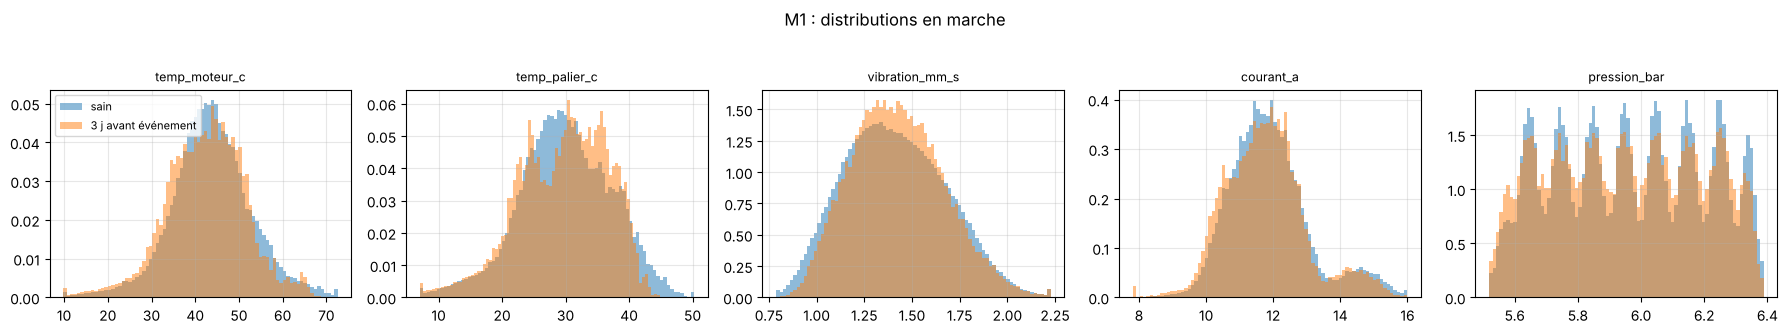

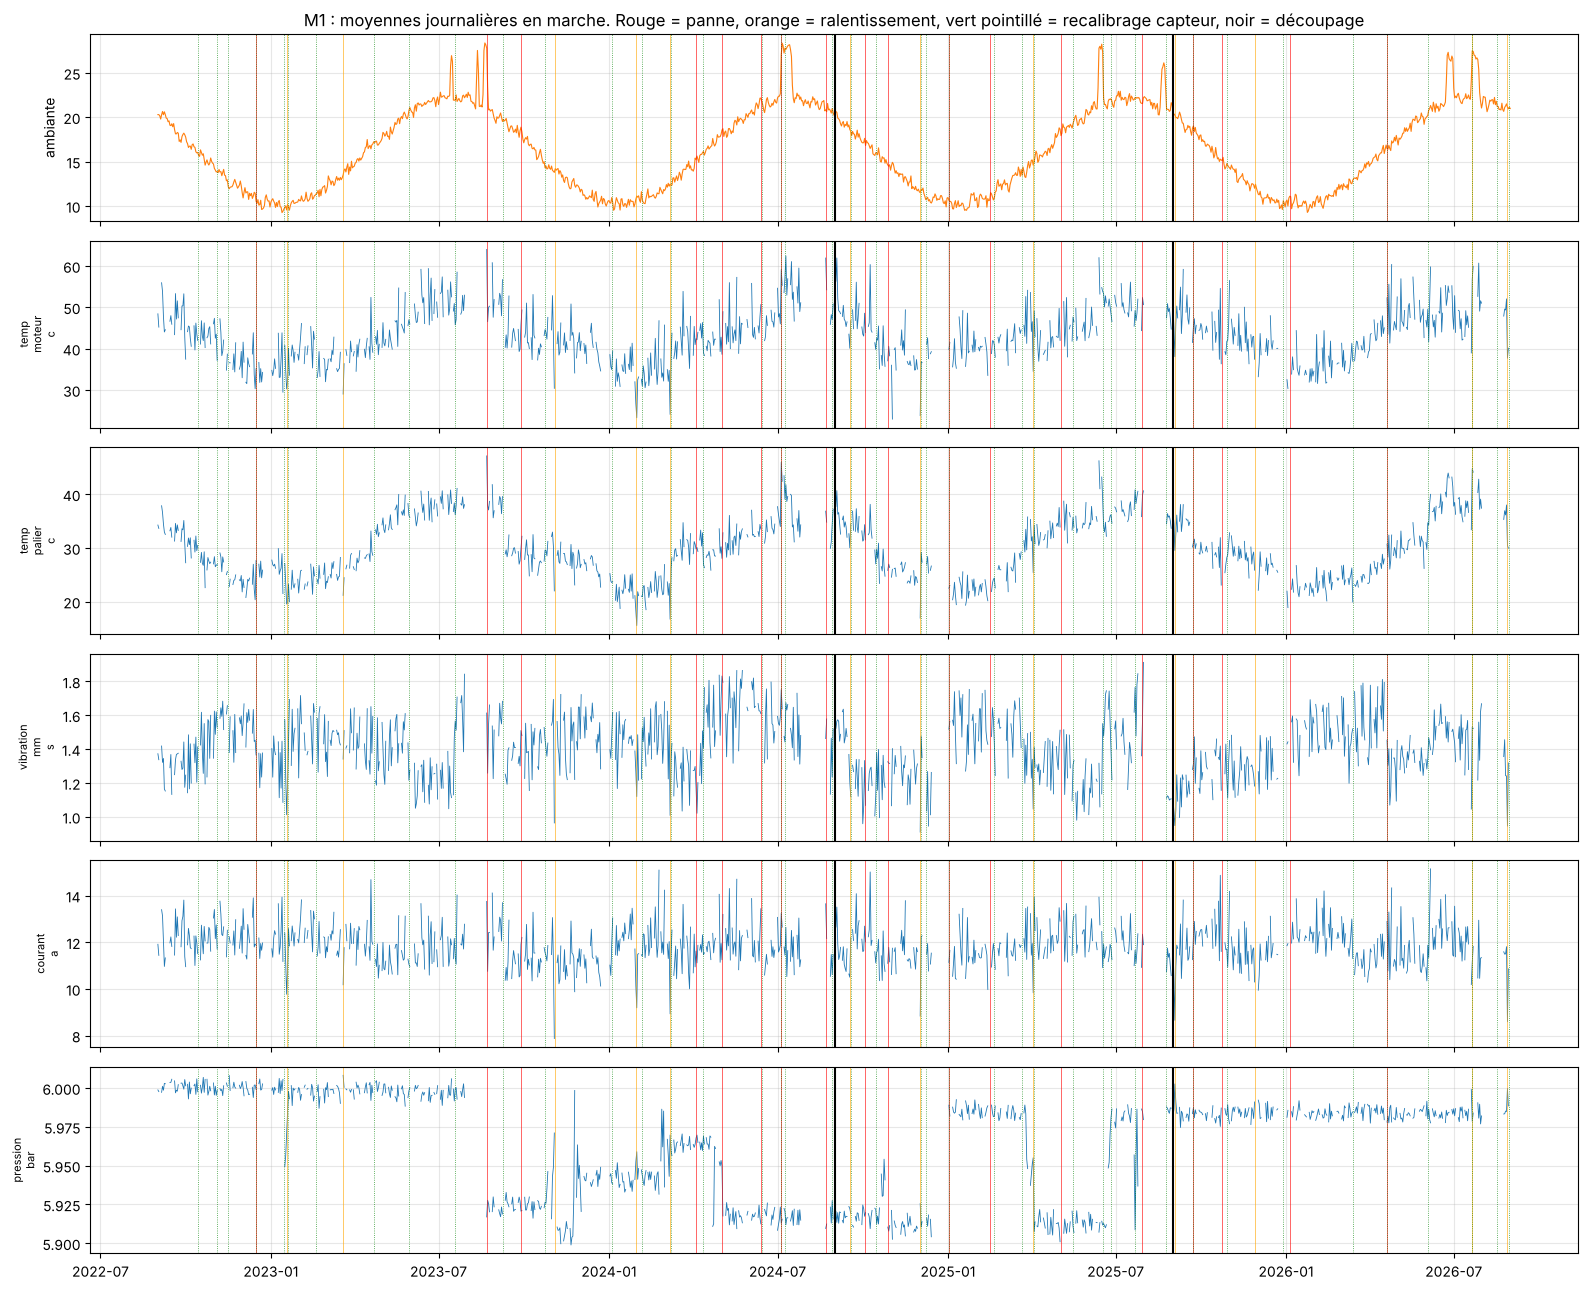

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))
r = raw["M1"]; run = r.running.to_numpy() == 1
pre = np.zeros(N, bool)
for _, f in ev[(ev.machine == "M1") & (ev.type != "electrique")].iterrows():
    b = int((f.evenement - T0).total_seconds() // 60); pre[b - 3 * 1440:b] = True
for ax, c in zip(axes, SENS):
    for msk, lab in [(SAIN["M1"] & run, "sain"), (pre & run, "3 j avant événement")]:
        ax.hist(r.loc[msk, c].dropna().clip(*r.loc[run, c].quantile([0.001, 0.999])), bins=80, density=True, alpha=0.5, label=lab)
    ax.set_title(c, fontsize=9)
axes[0].legend(fontsize=8); plt.suptitle("M1 : distributions en marche", y=1.03); plt.tight_layout()
plt.savefig(RES / "distributions.png", dpi=90, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(len(SENS) + 1, 1, figsize=(16, 13), sharex=True)
r = raw["M1"].set_index("timestamp"); rr = r[r.running == 1]
day = rr[SENS].resample("D").mean()
axes[0].plot(r.temp_ambiante_c.resample("D").mean(), lw=0.8, color="C1"); axes[0].set_ylabel("ambiante")
for ax, c in zip(axes[1:], SENS):
    ax.plot(day.index, day[c], lw=0.6); ax.set_ylabel(c.replace("_", "\n"), fontsize=8)
for ax in axes:
    for _, f in ev[ev.machine == "M1"].iterrows():
        ax.axvline(f.evenement, color="red" if f.issue == "panne" else "orange", lw=0.6, alpha=0.7)
    for _, b in ben[(ben.machine == "M1") & (ben.type == "recalibrage")].iterrows():
        ax.axvline(b.debut, color="green", lw=0.6, ls=":", alpha=0.8)
    for x in [TRAIN_END, VAL_END]: ax.axvline(x, color="k", lw=1.5)
axes[0].set_title("M1 : moyennes journalières en marche. Rouge = panne, orange = ralentissement, vert pointillé = recalibrage capteur, noir = découpage")
plt.tight_layout(); plt.savefig(RES / "quatre_ans_M1.png", dpi=80); plt.show()

### 2.5 Corrélations entre capteurs (en marche, M1)

In [7]:
cc = raw["M1"].loc[raw["M1"].running == 1, CH].corr().round(2)
cc

,speed,temp_ambiante_c,temp_moteur_c,temp_palier_c,vibration_mm_s,courant_a,pression_bar
speed,1.00,0.01,0.36,0.23,0.59,0.68,-0.02
temp_ambiante_c,0.01,1.00,0.60,0.81,-0.03,0.01,-0.02
temp_moteur_c,0.36,0.60,1.00,0.84,0.15,0.47,-0.02
temp_palier_c,0.23,0.81,0.84,1.00,0.06,0.23,-0.02
vibration_mm_s,0.59,-0.03,0.15,0.06,1.00,0.37,-0.01
courant_a,0.68,0.01,0.47,0.23,0.37,1.00,-0.01
pression_bar,-0.02,-0.02,-0.02,-0.02,-0.01,-0.01,1.00


## 3. Tokens

Chaque voie est d'abord normalisée par machine (médiane et écart interquartile calculés **sur la période d'entraînement seulement**). Un token = 15 minutes. Pour chaque voie, le token contient :
- le **niveau** (moyenne des 15 minutes) ;
- l'**amplitude** des variations (log de l'écart-type dans le token) ;
- la **forme** : les 15 valeurs centrées et réduites dans le token.

C'est la normalisation par « patch » courante dans les Transformers de séries temporelles (type PatchTST / RevIN). Elle sépare le niveau, que les événements bénins font beaucoup bouger, de la forme du signal, où se cache la dynamique. Ce n'est pas une caractéristique taillée pour un défaut : toutes les voies sont traitées de la même façon. Avec la fraction de valeurs manquantes par voie : 7 × (1 + 1 + 15) + 7 = 126 nombres par token.

In [8]:
NTOK = N // TOKM
TOK, NORM = {}, {}
for m in MACH:
    X = raw[m][CH].to_numpy(np.float32)
    tr = (raw[m].timestamp < TRAIN_END).to_numpy()
    med = np.nanmedian(X[tr], 0); iqr = np.nanpercentile(X[tr], 75, 0) - np.nanpercentile(X[tr], 25, 0)
    iqr = np.where(iqr < 1e-3, np.nanstd(X[tr], 0), iqr)
    NORM[m] = (med, iqr)
    Z = np.clip((X - med) / iqr, -8, 8)[:NTOK * TOKM].reshape(NTOK, TOKM, len(CH)).transpose(0, 2, 1)   # (token, voie, minute)
    miss = np.isnan(Z)
    mu = np.nanmean(Z, 2, keepdims=True); sd = np.nanstd(Z, 2, keepdims=True)
    shape = np.clip((Z - mu) / (sd + 0.01), -4, 4)
    shape[miss] = 0; mu = np.nan_to_num(mu); sd = np.nan_to_num(sd)
    TOK[m] = np.concatenate([mu[..., 0], np.log(sd[..., 0] + 0.01), shape.reshape(NTOK, -1), miss.mean(2)], 1).astype(np.float32)
D_TOK = TOK["M1"].shape[1]
print(f"{NTOK:,} tokens par machine, {D_TOK} nombres par token")

140,256 tokens par machine, 126 nombres par token


## 4. Cible et protocole

Une fenêtre se termine toutes les 2 h (au temps *t*). Étiquette = 1 si une panne ou un ralentissement commence dans ]t, t + 7 j]. Fenêtres **exclues** :
- pendant une intervention ou un ralentissement, et dans les 48 h qui suivent la fin d'une intervention (le système vient d'être réparé ; on ne le compte ni sain ni malade) ;
- pendant une dégradation interrompue par une maintenance préventive (cas censurés) ;
- moins de 2 h de marche dans les 24 h (week-ends, fermetures : rien à observer).

In [9]:
rows = []
for m in MACH:
    r = raw[m]; d = deg[deg.machine == m]
    run_cum = np.r_[0, np.cumsum(r.running.to_numpy())]
    excl = np.zeros(N + 1, bool); prec = np.zeros(N + 1, bool); ftype_at = np.full(N + 1, "", object)
    for _, f in d.iterrows():
        a = int((f.debut_degradation - T0).total_seconds() // 60); e = int((f.evenement - T0).total_seconds() // 60)
        b = int((f.fin_intervention - T0).total_seconds() // 60) + POST_REPAIR
        if f.issue == "preventif": excl[a:b] = True
        else:
            excl[e:b] = True; prec[a:e] = True; ftype_at[a:e] = f.type
    evt = np.sort(((ev[ev.machine == m].evenement - T0).dt.total_seconds() // 60).astype(int).to_numpy())
    evtype = ev[ev.machine == m].sort_values("evenement")
    hw = np.zeros(N + 1)
    for _, b_ in ben[ben.type == "canicule"].iterrows():
        a = int((b_.debut - T0).total_seconds() // 60); b2 = int((b_.fin - T0).total_seconds() // 60); hw[a:b2] = 1
    rec = np.sort(((ben[(ben.machine == m) & (ben.type == "recalibrage")].debut - T0).dt.total_seconds() // 60).astype(int).to_numpy())
    for e_tok in range(WIN, NTOK + 1, STRIDE):
        t = e_tok * TOKM
        j = np.searchsorted(evt, t, side="right")
        dt = evt[j] - t if j < len(evt) else 10 ** 9
        jr = np.searchsorted(rec, t, side="right") - 1
        rows.append(dict(machine=m, tok_end=e_tok, t=t, y=int(dt <= HOR), jours_avant=dt / 1440 if dt < 10 ** 9 else np.nan,
                         type_suivant=evtype.type.iloc[j] if j < len(evt) else "", issue_suivante=evtype.issue.iloc[j] if j < len(evt) else "",
                         marche_min=run_cum[t] - run_cum[t - WIN * TOKM], exclu=excl[t - 1], en_precurseur=prec[t - 1],
                         canicule=hw[t - 1] > 0, recal_7j=(jr >= 0) and (t - rec[jr] <= 7 * 1440)))
S = pd.DataFrame(rows)
S["time"] = T0 + pd.to_timedelta(S.t, unit="min")
S["split"] = np.where(S.time < TRAIN_END, "train", np.where(S.time < VAL_END, "val", "test"))
S["eval"] = (~S.exclu) & (S.marche_min >= MIN_RUN)
E = S[S["eval"]].copy()
print(E.groupby("split").agg(fenetres=("y", "size"), positifs=("y", "sum"), taux=("y", "mean")).loc[["train", "val", "test"]].round(3))
# les positifs électriques sont imprévisibles : gardés dans la cible (honnêteté), et rapportés à part

       fenetres  positifs   taux
split                           
train     22054      3723  0.169
val       11250      2350  0.209
test      10636      2133  0.201


## 5. Baselines

### 5.1 Caractéristiques par token

Pour chaque token et chaque capteur : moyenne en marche, et autocorrélations à 1, 2, 4 et 8 minutes du signal centré dans le token. Ensuite, un **modèle physique sain** par machine et par capteur : régression ridge du capteur sur la vitesse (bases radiales), la charge filtrée à 5, 15, 30, 60 et 120 min, la marche filtrée et l'ambiante, apprise sur les minutes saines d'entraînement. Le résidu mesure l'écart à ce comportement attendu.

In [10]:
def lowpass(x, tau): a = math.exp(-1 / tau); return lfilter([1 - a], [1, -a], x)
def phys_features(r):
    sp = r.speed.to_numpy(float); run = r.running.to_numpy(float)
    feats = [np.exp(-0.5 * ((sp - c) / 0.12) ** 2) for c in np.linspace(0.3, 1.3, 9)]
    feats += [lowpass(sp, t) for t in (5, 15, 30, 60, 120)] + [lowpass(sp, t) ** 2 for t in (15, 60)]
    feats += [lowpass(run, t) for t in (5, 30, 120)] + [run, r.temp_ambiante_c.ffill().bfill().to_numpy()]
    return np.stack(feats, 1).astype(np.float32)

TOKF = {}
for m in MACH:
    r = raw[m]; run = r.running.to_numpy()[:NTOK * TOKM].reshape(NTOK, TOKM)
    Xf = phys_features(r)[:NTOK * TOKM]
    h = (SAIN[m] & (r.timestamp < TRAIN_END).to_numpy())[:NTOK * TOKM]
    out = {"run": run.mean(1)}
    for c in SENS:
        x = r[c].to_numpy(float)[:NTOK * TOKM]; ok = ~np.isnan(x)
        fit = h & ok & ((run.ravel() == 1) if c != "pression_bar" else True)
        idx = np.random.default_rng(0).choice(np.flatnonzero(fit), min(400_000, fit.sum()), replace=False)
        reg = Ridge(alpha=1.0).fit(Xf[idx], x[idx])
        res = np.where(ok, x - reg.predict(Xf), np.nan).reshape(NTOK, TOKM)
        xt = x.reshape(NTOK, TOKM); w = run if c != "pression_bar" else np.ones_like(run)
        with np.errstate(invalid="ignore", divide="ignore"):
            out[f"{c}_moy"] = np.nansum(np.where(w == 1, xt, 0), 1) / np.maximum(w.sum(1), 1)
            out[f"{c}_res_moy"] = np.nanmean(res, 1); out[f"{c}_res_ec"] = np.nanstd(res, 1)
            dct = xt - np.nanmean(xt, 1, keepdims=True); den = np.nansum(dct ** 2, 1) + 1e-9
            for L in (1, 2, 4, 8):
                out[f"{c}_ac{L}"] = np.nansum(dct[:, L:] * dct[:, :-L], 1) / den
    dI = np.diff(r.courant_a.to_numpy(float)[:NTOK * TOKM].reshape(NTOK, TOKM), axis=1)
    dV = np.diff(r.vibration_mm_s.to_numpy(float)[:NTOK * TOKM].reshape(NTOK, TOKM), axis=1)
    out["corr_dI_dV"] = np.nansum(dI * dV, 1) / np.sqrt(np.nansum(dI ** 2, 1) * np.nansum(dV ** 2, 1) + 1e-9)
    TOKF[m] = pd.DataFrame(out)
print("caractéristiques par token :", TOKF["M1"].shape[1], f"({time.time() - t_start:.0f} s écoulées)")

caractéristiques par token : 37 (48 s écoulées)


### 5.2 Caractéristiques par fenêtre de 24 h

Moyennes pondérées par la marche (tokens en marche à au moins 80 % pour les autocorrélations et les résidus), puis scores non supervisés :
- **seuil de niveau** : max des |z| du niveau moyen 24 h (z calculé sur les fenêtres saines d'entraînement de la machine) ;
- **EWMA 3 jours** : même chose après lissage exponentiel des niveaux sur 36 fenêtres ;
- **résidus physiques** : max des z de l'écart-type des résidus, lissé sur 12 fenêtres (24 h).

In [11]:
def window_features(m):
    f = TOKF[m]; s = S[S.machine == m]
    run_tok = f.run.to_numpy(); good = run_tok >= 0.8
    cols_lvl = [f"{c}_moy" for c in SENS]
    cols_dyn = [c for c in f.columns if c not in cols_lvl + ["run"]]
    cs_w = np.vstack([np.zeros(1), np.cumsum(run_tok)[:, None]])[:, 0]
    out = {}
    lvl = f[cols_lvl].fillna(0).to_numpy() * run_tok[:, None]
    cs = np.vstack([np.zeros((1, len(cols_lvl))), np.cumsum(lvl, 0)])
    e = s.tok_end.to_numpy(); b = e - WIN
    wsum = cs_w[e] - cs_w[b]
    for i, c in enumerate(cols_lvl):
        out[c] = (cs[e, i] - cs[b, i]) / np.maximum(wsum, 1e-6)
    dyn = f[cols_dyn].to_numpy(); valid = good[:, None] & ~np.isnan(dyn)
    csd = np.vstack([np.zeros((1, len(cols_dyn))), np.cumsum(np.where(valid, dyn, 0), 0)])
    csn = np.vstack([np.zeros((1, len(cols_dyn))), np.cumsum(valid, 0)])
    for i, c in enumerate(cols_dyn):
        n_ = csn[e, i] - csn[b, i]
        out[c] = np.where(n_ > 0, (csd[e, i] - csd[b, i]) / np.maximum(n_, 1), np.nan)
    out["marche_frac"] = wsum / WIN
    return pd.DataFrame(out, index=s.index)

WF = pd.concat([window_features(m) for m in MACH]).loc[S.index]
FEAT = list(WF.columns)
ref = S["eval"] & (S.split == "train") & (S.y == 0) & (~S.en_precurseur)

def zscore_per_machine(df, ref_mask):
    out = df.copy()
    for m in MACH:
        mm = S.machine == m
        mu = df[mm & ref_mask].mean(); sd = df[mm & ref_mask].std() + 1e-9
        out.loc[mm] = (df[mm] - mu) / sd
    return out

def ewm_per_machine(df, span):
    return pd.concat([df[S.machine == m].ewm(span=span, ignore_na=True).mean() for m in MACH]).loc[df.index]

lvl_cols = [f"{c}_moy" for c in SENS]
res_cols = [f"{c}_res_ec" for c in SENS]
SC = pd.DataFrame(index=S.index)
SC["Seuil niveau (max |z|)"] = zscore_per_machine(WF[lvl_cols], ref).abs().max(1)
SC["EWMA 3 j niveaux"] = zscore_per_machine(ewm_per_machine(WF[lvl_cols], 36), ref).abs().max(1)
SC["Résidus physiques (lissés 24 h)"] = ewm_per_machine(zscore_per_machine(WF[res_cols], ref), 12).max(1)
print(f"baselines non supervisées prêtes ({time.time() - t_start:.0f} s)")

/tmp/ipykernel_6012/3520469774.py:41: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  SC["Seuil niveau (max |z|)"] = zscore_per_machine(WF[lvl_cols], ref).abs().max(1)
/tmp/ipykernel_6012/3520469774.py:42: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  SC["EWMA 3 j niveaux"] = zscore_per_machine(ewm_per_machine(WF[lvl_cols], 36), ref).abs().max(1)


baselines non supervisées prêtes (49 s)


/tmp/ipykernel_6012/3520469774.py:43: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  SC["Résidus physiques (lissés 24 h)"] = ewm_per_machine(zscore_per_machine(WF[res_cols], ref), 12).max(1)


### 5.3 Baselines supervisées

Régression logistique et boosting (HistGradientBoosting) sur les ~100 caractéristiques de fenêtre z-normalisées par machine, plus les mêmes lissées sur 24 h. Hyperparamètres choisis sur la validation (ROC-AUC). Entraînement sur les fenêtres d'entraînement seulement.

In [12]:
WFZ = zscore_per_machine(WF, ref)
XF = pd.concat([WFZ, ewm_per_machine(WFZ, 12).add_suffix("_l24h")], axis=1)
tr_m = (E.split == "train").to_numpy(); va_m = (E.split == "val").to_numpy(); te_m = (E.split == "test").to_numpy()
yE = E.y.to_numpy()

def fit_select(make_models, X):
    best = None
    for name, mk in make_models:
        mdl = mk().fit(X[tr_m], yE[tr_m])
        auc = roc_auc_score(yE[va_m], mdl.predict_proba(X[va_m])[:, 1])
        if best is None or auc > best[0]: best = (auc, name, mdl)
    return best[2], best[1], best[0]

Xh = XF.loc[E.index].fillna(0).to_numpy()
gbm_grid = [(f"lr={lr}, feuilles={ml}", (lambda lr=lr, ml=ml: HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=ml, max_iter=300, l2_regularization=1.0, random_state=0)))
            for lr in (0.03, 0.1) for ml in (15, 31)]
lr_grid = [(f"C={C}", (lambda C=C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000)))) for C in (0.01, 0.1, 1.0)]
PRED = {}  # nom -> score sur E (toutes périodes)
for nm, grid in [("Boosting caractéristiques expertes", gbm_grid), ("Logistique caractéristiques expertes", lr_grid)]:
    mdl, hp, auc_v = fit_select(grid, Xh)
    PRED[nm] = mdl.predict_proba(Xh)[:, 1]
    print(f"{nm:<40} {hp:<22} AUC validation {auc_v:.3f}")
for c in SC.columns: PRED[c] = SC.loc[E.index, c].to_numpy()
print(f"({time.time() - t_start:.0f} s)")

Boosting caractéristiques expertes       lr=0.1, feuilles=15    AUC validation 0.690


Logistique caractéristiques expertes     C=0.1                  AUC validation 0.694
(61 s)


## 6. JEPA

**Architecture.** Projection linéaire des tokens (126 → 96) + position apprise, encodeur Transformer (4 couches, 4 têtes, d = 96). Pendant le pré-entraînement, 4 blocs de 6 tokens (≈ 25 % de la fenêtre) sont masqués dans l'entrée de l'**encodeur de contexte** ; un **prédicteur** (2 couches) doit retrouver, à ces positions, la représentation produite par un **encodeur cible** (moyenne mobile exponentielle des poids de l'encodeur de contexte, qui voit la fenêtre complète). La perte est calculée **dans l'espace latent**, pas sur les valeurs brutes : c'est le principe JEPA.

**Données de pré-entraînement** : fenêtres de 24 h tirées au hasard dans la période d'entraînement des 4 machines (au moins 2 h de marche), **sans aucune étiquette**.

**Utilisation ensuite**
- **surprise** : erreur de prédiction moyenne sur 2 masques fixes (8 blocs de 6 tokens au total) ; une dynamique jamais vue en entraînement devrait être mal prédite ; z-normalisée par machine, lissée sur 24 h ;
- **représentation** : moyenne des sorties de l'encodeur cible sur toute la fenêtre, sur les tokens en marche (pondérée par la fraction de marche) et sur les 4 dernières heures (288 nombres), donnée à une sonde logistique ou à un boosting ;
- **contrôle** : même encodeur avec des poids aléatoires, même sonde. Si le pré-entraînement n'apporte rien, les deux se valent.

In [13]:
class Encoder(nn.Module):
    def __init__(self, d_in, d=96, L=WIN, depth=4, heads=4):
        super().__init__()
        self.proj = nn.Linear(d_in, d); self.pos = nn.Parameter(torch.randn(1, L, d) * 0.02)
        self.mask_tok = nn.Parameter(torch.zeros(1, 1, d))
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.tr = nn.TransformerEncoder(layer, depth); self.norm = nn.LayerNorm(d)
    def forward(self, x, mask=None):
        h = self.proj(x)
        if mask is not None: h = torch.where(mask[..., None], self.mask_tok.expand_as(h), h)
        return self.norm(self.tr(h + self.pos))

class Predictor(nn.Module):
    def __init__(self, d=96, L=WIN, depth=2, heads=4):
        super().__init__()
        self.pos = nn.Parameter(torch.randn(1, L, d) * 0.02); self.mask_tok = nn.Parameter(torch.zeros(1, 1, d))
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.tr = nn.TransformerEncoder(layer, depth); self.out = nn.Linear(d, d)
    def forward(self, ctx, mask):
        h = torch.where(mask[..., None], self.mask_tok.expand_as(ctx), ctx) + self.pos
        return self.out(self.tr(h))

def random_masks(B, rng, n_blocks=4, blen=6):
    m = np.zeros((B, WIN), bool)
    for i in range(B):
        for s in rng.integers(0, WIN - blen, n_blocks): m[i, s:s + blen] = True
    return torch.from_numpy(m)

FIXED_MASKS = torch.zeros(2, WIN, dtype=torch.bool)
for k in range(2):
    for s in range(k * 12, WIN - 6, 24): FIXED_MASKS[k, s:s + 6] = True   # 4 blocs de 6 tokens ; le 2e masque est décalé de 12 tokens

# fenêtres de pré-entraînement : tous les débuts possibles dans la période d'entraînement
pre_idx = []
for mi, m in enumerate(MACH):
    run_tok = TOKF[m].run.to_numpy(); csr = np.r_[0, np.cumsum(run_tok)]
    t_end_train = int((TRAIN_END - T0).total_seconds() // 60) // TOKM
    starts = np.arange(0, t_end_train - WIN)
    ok = (csr[starts + WIN] - csr[starts]) * TOKM >= MIN_RUN
    pre_idx += [(mi, s) for s in starts[ok]]
pre_idx = np.array(pre_idx)
TOKT = {m: torch.from_numpy(TOK[m]) for m in MACH}
RUNT = {m: torch.tensor(TOKF[m].run.to_numpy(), dtype=torch.float32) for m in MACH}   # fraction de marche par token
def batch_from(idx):
    return torch.stack([TOKT[MACH[mi]][s:s + WIN] for mi, s in idx])
print(f"{len(pre_idx):,} fenêtres possibles pour le pré-entraînement")

def pretrain(seed, epochs=EPOCHS, steps=STEPS_PER_EPOCH, B=128):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    enc = Encoder(D_TOK); pred = Predictor(); tgt = Encoder(D_TOK); tgt.load_state_dict(enc.state_dict())
    for p in tgt.parameters(): p.requires_grad_(False)
    opt = torch.optim.AdamW(list(enc.parameters()) + list(pred.parameters()), lr=5e-4, weight_decay=0.05)
    total = epochs * steps; sched = torch.optim.lr_scheduler.OneCycleLR(opt, 5e-4, total_steps=total, pct_start=0.1)
    hist = []; step = 0
    for ep in range(epochs):
        tot = 0.0
        for _ in range(steps):
            x = batch_from(pre_idx[rng.integers(0, len(pre_idx), B)]); mask = random_masks(B, rng)
            with torch.no_grad(): target = F.layer_norm(tgt(x), (96,))
            p = pred(enc(x, mask), mask)
            loss = F.smooth_l1_loss(p[mask], target[mask])
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(enc.parameters(), 1.0); opt.step(); sched.step()
            mom = 0.996 + (1 - 0.996) * step / total; step += 1
            with torch.no_grad():
                for pt, pe in zip(tgt.parameters(), enc.parameters()): pt.mul_(mom).add_(pe.detach(), alpha=1 - mom)
            tot += loss.item()
        hist.append(tot / steps)
        if ep % 5 == 4 or ep == epochs - 1: print(f"  graine {seed}, époque {ep + 1}/{epochs} : perte {hist[-1]:.4f}", flush=True)
    return enc, pred, tgt, hist

@torch.inference_mode()
def embed_and_surprise(enc, pred, tgt, B=512, surprise=True):
    enc.eval(); tgt.eval()
    if pred is not None: pred.eval()
    emb, sur = [], []
    idx = np.array([(MACH.index(m), e - WIN) for m, e in zip(S.machine, S.tok_end)])
    for i in range(0, len(idx), B):
        x = batch_from(idx[i:i + B]); z = tgt(x)
        w = torch.stack([RUNT[MACH[mi]][s:s + WIN] for mi, s in idx[i:i + B]])[..., None]
        emb.append(torch.cat([z.mean(1), (z * w).sum(1) / (w.sum(1) + 1e-6), z[:, -16:].mean(1)], 1).numpy())
        if not surprise: continue
        target = F.layer_norm(z, (96,)); err = torch.zeros(len(x))
        for k in range(len(FIXED_MASKS)):
            mk = FIXED_MASKS[k].expand(len(x), -1)
            p = pred(enc(x, mk), mk)
            err += ((p - target) ** 2).mean(-1)[:, FIXED_MASKS[k]].mean(1)
        sur.append((err / len(FIXED_MASKS)).numpy())
    return np.concatenate(emb), (np.concatenate(sur) if surprise else None)

203,653 fenêtres possibles pour le pré-entraînement


graine 0 : perte 0.150 → 0.063 (poids relus), 232 s


graine 1 : perte 0.152 → 0.060 (poids relus), 195 s


graine 2 : perte 0.151 → 0.084 (poids relus), 203 s


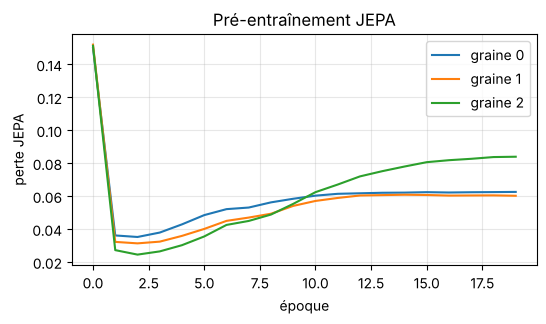

In [14]:
# Pré-entraînement : environ 25 min par graine sur 4 cœurs CPU. Si les poids existent déjà (results_capteurs_4ans/jepa_seed*.pt)
# et que RECALCULER_JEPA vaut False, on les relit et on recalcule seulement les représentations (environ 4 min par graine).
hist_file = RES / "historique_pretraining.json"
deja = all((RES / f"jepa_seed{s_}.pt").exists() for s_ in SEEDS) and hist_file.exists()
HIST = json.load(open(hist_file)) if deja else {}
JEPA = {}
for seed in SEEDS:
    t1 = time.time()
    if RECALCULER_JEPA or not deja:
        enc, pred, tgt, hist = pretrain(seed)
        torch.save({"enc": enc.state_dict(), "pred": pred.state_dict(), "tgt": tgt.state_dict()}, RES / f"jepa_seed{seed}.pt")
        HIST[str(seed)] = hist
    else:
        enc, pred, tgt = Encoder(D_TOK), Predictor(), Encoder(D_TOK)
        w = torch.load(RES / f"jepa_seed{seed}.pt")
        enc.load_state_dict(w["enc"]); pred.load_state_dict(w["pred"]); tgt.load_state_dict(w["tgt"])
    emb, sur = embed_and_surprise(enc, pred, tgt)
    torch.manual_seed(1000 + seed); r_enc = Encoder(D_TOK)          # contrôle : mêmes poids aléatoires à chaque exécution
    emb_r, _ = embed_and_surprise(r_enc, None, r_enc, surprise=False)
    JEPA[seed] = dict(emb=emb, sur=sur, emb_rand=emb_r, hist=HIST[str(seed)])
    h = HIST[str(seed)]
    print(f"graine {seed} : perte {h[0]:.3f} → {h[-1]:.3f} ({'pré-entraînée' if RECALCULER_JEPA or not deja else 'poids relus'}), {time.time() - t1:.0f} s")
json.dump(HIST, open(hist_file, "w"))
plt.figure(figsize=(6, 3))
for s_, v in JEPA.items(): plt.plot(v["hist"], label=f"graine {s_}")
plt.xlabel("époque"); plt.ylabel("perte JEPA"); plt.legend(); plt.title("Pré-entraînement JEPA"); plt.show()

### 6.1 Têtes sur les représentations JEPA (encodeur gelé)

Pour chaque graine :
- **distance à la normale** (non supervisé) : distance de Mahalanobis de la représentation « tokens en marche » aux fenêtres saines d'entraînement de la même machine (16 composantes principales blanchies), lissée sur 24 h. La surprise mesure une incohérence *à l'intérieur* de la fenêtre ; une dégradation installée est cohérente sur 24 h, d'où ce second score ;
- **sonde logistique** (C choisi sur la validation) sur la représentation z-normalisée par machine et lissée sur 24 h ;
- **boosting experts + JEPA** : le boosting de la section 5.3 auquel on ajoute 32 composantes principales de la représentation JEPA. Il mesure si JEPA apporte une information que les caractéristiques expertes n'ont pas.

On rapporte l'**ensemble** des graines (moyenne des rangs) et l'AUC de chaque graine.

In [15]:
from sklearn.decomposition import PCA

def jepa_probe(emb):
    Zz = zscore_per_machine(pd.DataFrame(emb, index=S.index), ref)
    Zf = pd.concat([Zz, ewm_per_machine(Zz, 12).add_suffix("_l")], axis=1).loc[E.index].fillna(0).to_numpy()
    mdl, _, _ = fit_select(lr_grid, Zf)
    return mdl.predict_proba(Zf)[:, 1]

def dist_normale(emb):
    Zr = emb[:, 96:192]; out = np.zeros(len(S))
    for m in MACH:
        mm = (S.machine == m).to_numpy(); r_ = (ref & (S.machine == m)).to_numpy()
        pca = PCA(16, whiten=True, random_state=0).fit(Zr[r_]); out[mm] = (pca.transform(Zr[mm]) ** 2).sum(1)
    d = pd.DataFrame({"d": np.log1p(out)}, index=S.index)
    return ewm_per_machine(zscore_per_machine(d, ref), 12).loc[E.index, "d"].to_numpy()

def experts_plus_jepa(emb):
    Zz = zscore_per_machine(pd.DataFrame(emb, index=S.index), ref).fillna(0)
    P = PCA(32, random_state=0).fit(Zz[ref].to_numpy()).transform(Zz.to_numpy())
    P = pd.DataFrame(P, index=S.index).add_prefix("jepa_pc")
    X_ = pd.concat([XF, P, ewm_per_machine(P, 12).add_suffix("_l24h")], axis=1).loc[E.index].fillna(0).to_numpy()
    mdl, _, _ = fit_select(gbm_grid, X_)
    return mdl.predict_proba(X_)[:, 1]

PER_SEED = {}
for s_, v in JEPA.items():
    t1 = time.time(); d = {}
    sur = pd.DataFrame({"s": v["sur"]}, index=S.index)
    d["JEPA surprise (non supervisé)"] = ewm_per_machine(zscore_per_machine(sur, ref), 12).loc[E.index, "s"].to_numpy()
    d["JEPA distance à la normale (non supervisé)"] = dist_normale(v["emb"])
    d["JEPA sonde logistique"] = jepa_probe(v["emb"])
    d["Encodeur aléatoire sonde logistique"] = jepa_probe(v["emb_rand"])
    d["Boosting experts + JEPA"] = experts_plus_jepa(v["emb"])
    PER_SEED[s_] = d
    print(f"graine {s_} : têtes en {time.time() - t1:.0f} s")

graine 0 : têtes en 76 s


graine 1 : têtes en 78 s


graine 2 : têtes en 74 s


### 6.2 Fine-tuning supervisé de l'encodeur

L'encodeur cible JEPA est repris tel quel, une tête linéaire est posée sur la moyenne des tokens en marche et des 4 dernières heures, et **tout** est entraîné sur les étiquettes d'entraînement (6 époques de 150 lots, on garde l'époque la meilleure en validation). Même chose depuis des **poids aléatoires** : l'écart entre les deux mesure ce que le pré-entraînement apporte quand on dispose d'étiquettes. Les probabilités sont lissées sur 24 h comme pour les autres têtes.

In [16]:
class Classifier(nn.Module):
    def __init__(self, enc):
        super().__init__(); self.enc = enc; self.head = nn.Sequential(nn.LayerNorm(192), nn.Linear(192, 1))
    def forward(self, x, w):
        z = self.enc(x)
        return self.head(torch.cat([(z * w).sum(1) / (w.sum(1) + 1e-6), z[:, -16:].mean(1)], 1))[:, 0]

E_IDX = np.array([(MACH.index(m), e - WIN) for m, e in zip(E.machine, E.tok_end)])
def batch_w(idx): return torch.stack([RUNT[MACH[mi]][s:s + WIN] for mi, s in idx])[..., None]
def smooth_rows(p, rows):
    return pd.Series(p, index=E.index[rows]).groupby(E.machine.to_numpy()[rows]).transform(lambda x: x.ewm(span=12).mean()).to_numpy()

@torch.inference_mode()
def predict_rows(model, rows, B=512):
    model.eval(); out = []
    for i in range(0, len(rows), B):
        idx = E_IDX[rows[i:i + B]]; out.append(model(batch_from(idx), batch_w(idx)).numpy())
    return np.concatenate(out)

def finetune(enc_state, seed, epochs=6, steps=150, B=128):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    enc = Encoder(D_TOK)
    if enc_state is not None: enc.load_state_dict(enc_state)
    model = Classifier(enc)
    opt = torch.optim.AdamW([{"params": model.enc.parameters(), "lr": 2e-4}, {"params": model.head.parameters(), "lr": 1e-3}], weight_decay=0.05)
    tr_rows, va_rows = np.flatnonzero(tr_m), np.flatnonzero(va_m)
    yt_ = torch.tensor(yE, dtype=torch.float32); best = (-1, None)
    for ep in range(epochs):
        model.train()
        for _ in range(steps):
            r_ = rng.choice(tr_rows, B); idx = E_IDX[r_]
            loss = F.binary_cross_entropy_with_logits(model(batch_from(idx), batch_w(idx)), yt_[r_])
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        auc_v = roc_auc_score(yE[va_rows], smooth_rows(predict_rows(model, va_rows), va_rows))
        if auc_v > best[0]: best = (auc_v, {k: v.clone() for k, v in model.state_dict().items()}, ep + 1)
    model.load_state_dict(best[1]); all_rows = np.arange(len(E))
    return smooth_rows(predict_rows(model, all_rows), all_rows), best[0], best[2]

cache_ft = RES / "scores_finetune.pkl"
if RECALCULER_JEPA or not cache_ft.exists():
    FT = {}
    for s_ in SEEDS:
        t1 = time.time(); st = torch.load(RES / f"jepa_seed{s_}.pt")["tgt"]
        p_j, a_j, ep_j = finetune(st, s_); p_r, a_r, ep_r = finetune(None, s_)
        FT[s_] = {"JEPA fine-tuné": p_j, "Encodeur aléatoire fine-tuné": p_r}
        print(f"graine {s_} : AUC validation JEPA {a_j:.3f} (époque {ep_j}), aléatoire {a_r:.3f} (époque {ep_r}), {time.time() - t1:.0f} s")
    pickle.dump(FT, open(cache_ft, "wb"))
else:
    FT = pickle.load(open(cache_ft, "rb")); print("fine-tuning relu depuis", cache_ft)
for s_ in SEEDS: PER_SEED[s_].update(FT[s_])

fine-tuning relu depuis results_capteurs_4ans/scores_finetune.pkl


### 6.3 Comparaison : autoencodeur masqué (ajoutée le 15/10/2026 à la demande d'Antoine)

Pour savoir si c'est l'objectif **JEPA** (prédire dans l'espace latent) qui compte, on refait exactement le même protocole avec un **autoencodeur masqué** (type MAE) :
- même encodeur Transformer (4 couches, d = 96), mêmes tokens, mêmes masques, mêmes lots tirés (même graine), mêmes 20 époques ;
- la seule différence : le décodeur (même taille que le prédicteur JEPA) doit **reconstruire les valeurs brutes** des tokens masqués (erreur quadratique), au lieu de prédire leur représentation latente. Pas d'encodeur cible ni de moyenne mobile.

On applique ensuite les mêmes têtes : erreur de reconstruction (l'équivalent de la surprise), distance à la normale, sonde logistique, fine-tuning. Un autoencodeur **sans** masque n'aurait pas de sens ici : un Transformer sans goulot d'étranglement apprend l'identité.

  graine 0, époque 5/20 : perte 0.2600


  graine 0, époque 10/20 : perte 0.2489


  graine 0, époque 15/20 : perte 0.2462


  graine 0, époque 20/20 : perte 0.2456


graine 0 : autoencodeur, perte 0.528 → 0.246 (pré-entraîné), 1222 s


...

  graine 2, époque 20/20 : perte 0.2448


graine 2 : autoencodeur, perte 0.552 → 0.245 (pré-entraîné), 1260 s


graine 0 : AUC validation autoencodeur fine-tuné 0.651 (époque 3), 219 s


graine 1 : AUC validation autoencodeur fine-tuné 0.648 (époque 5), 210 s


graine 2 : AUC validation autoencodeur fine-tuné 0.646 (époque 2), 225 s


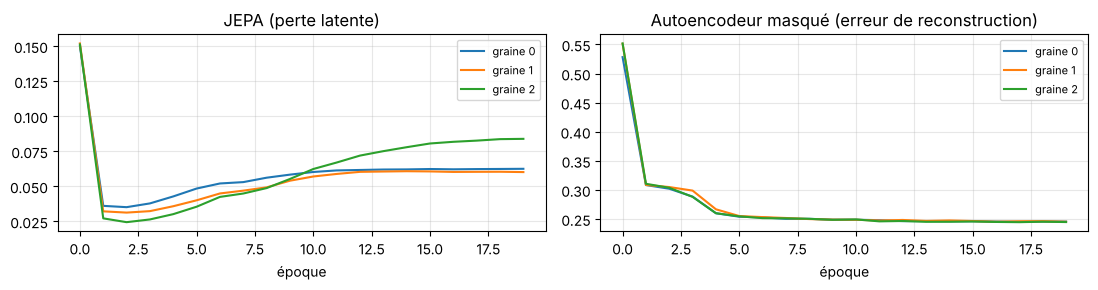

In [17]:
def make_decoder():
    dec = Predictor(); dec.out = nn.Linear(96, D_TOK)   # même architecture que le prédicteur JEPA, sortie = token brut
    return dec

def pretrain_ae(seed, epochs=EPOCHS, steps=STEPS_PER_EPOCH, B=128):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)   # mêmes lots et mêmes masques que JEPA
    enc = Encoder(D_TOK); dec = make_decoder()
    opt = torch.optim.AdamW(list(enc.parameters()) + list(dec.parameters()), lr=5e-4, weight_decay=0.05)
    total = epochs * steps; sched = torch.optim.lr_scheduler.OneCycleLR(opt, 5e-4, total_steps=total, pct_start=0.1)
    hist = []
    for ep in range(epochs):
        tot = 0.0
        for _ in range(steps):
            x = batch_from(pre_idx[rng.integers(0, len(pre_idx), B)]); mask = random_masks(B, rng)
            rec = dec(enc(x, mask), mask)
            loss = F.mse_loss(rec[mask], x[mask])
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(enc.parameters(), 1.0); opt.step(); sched.step()
            tot += loss.item()
        hist.append(tot / steps)
        if ep % 5 == 4 or ep == epochs - 1: print(f"  graine {seed}, époque {ep + 1}/{epochs} : perte {hist[-1]:.4f}", flush=True)
    return enc, dec, hist

@torch.inference_mode()
def ae_recon_error(enc, dec, B=512):
    enc.eval(); dec.eval(); out = []
    idx = np.array([(MACH.index(m), e - WIN) for m, e in zip(S.machine, S.tok_end)])
    for i in range(0, len(idx), B):
        x = batch_from(idx[i:i + B]); err = torch.zeros(len(x))
        for k in range(len(FIXED_MASKS)):
            mk = FIXED_MASKS[k].expand(len(x), -1)
            err += ((dec(enc(x, mk), mk) - x) ** 2).mean(-1)[:, FIXED_MASKS[k]].mean(1)
        out.append((err / len(FIXED_MASKS)).numpy())
    return np.concatenate(out)

hist_ae_file = RES / "historique_autoencodeur.json"
deja_ae = all((RES / f"autoencodeur_seed{s_}.pt").exists() for s_ in SEEDS) and hist_ae_file.exists()
HIST_AE = json.load(open(hist_ae_file)) if deja_ae else {}
for seed in SEEDS:
    t1 = time.time()
    if RECALCULER_JEPA or not deja_ae:
        enc, dec, hist = pretrain_ae(seed)
        torch.save({"enc": enc.state_dict(), "dec": dec.state_dict()}, RES / f"autoencodeur_seed{seed}.pt"); HIST_AE[str(seed)] = hist
    else:
        enc, dec = Encoder(D_TOK), make_decoder(); w = torch.load(RES / f"autoencodeur_seed{seed}.pt")
        enc.load_state_dict(w["enc"]); dec.load_state_dict(w["dec"])
    emb, _ = embed_and_surprise(enc, None, enc, surprise=False)
    rec_err = pd.DataFrame({"r": ae_recon_error(enc, dec)}, index=S.index)
    d = PER_SEED[seed]
    d["Autoencodeur erreur de reconstruction (non supervisé)"] = ewm_per_machine(zscore_per_machine(rec_err, ref), 12).loc[E.index, "r"].to_numpy()
    d["Autoencodeur distance à la normale (non supervisé)"] = dist_normale(emb)
    d["Autoencodeur sonde logistique"] = jepa_probe(emb)
    h = HIST_AE[str(seed)]
    print(f"graine {seed} : autoencodeur, perte {h[0]:.3f} → {h[-1]:.3f} ({'pré-entraîné' if RECALCULER_JEPA or not deja_ae else 'poids relus'}), {time.time() - t1:.0f} s")
json.dump(HIST_AE, open(hist_ae_file, "w"))

cache_ft_ae = RES / "scores_finetune_autoencodeur.pkl"
if RECALCULER_JEPA or not cache_ft_ae.exists():
    FT_AE = {}
    for s_ in SEEDS:
        t1 = time.time(); st = torch.load(RES / f"autoencodeur_seed{s_}.pt")["enc"]
        p_a, a_a, ep_a = finetune(st, s_)
        FT_AE[s_] = {"Autoencodeur fine-tuné": p_a}
        print(f"graine {s_} : AUC validation autoencodeur fine-tuné {a_a:.3f} (époque {ep_a}), {time.time() - t1:.0f} s")
    pickle.dump(FT_AE, open(cache_ft_ae, "wb"))
else:
    FT_AE = pickle.load(open(cache_ft_ae, "rb")); print("fine-tuning autoencodeur relu depuis", cache_ft_ae)
for s_ in SEEDS: PER_SEED[s_].update(FT_AE[s_])

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for s_ in SEEDS:
    axes[0].plot(HIST[str(s_)], label=f"graine {s_}"); axes[1].plot(HIST_AE[str(s_)], label=f"graine {s_}")
axes[0].set_title("JEPA (perte latente)"); axes[1].set_title("Autoencodeur masqué (erreur de reconstruction)")
for ax in axes: ax.set_xlabel("époque"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

def rank(x): return pd.Series(x).rank(pct=True).to_numpy()
for k in PER_SEED[SEEDS[0]]:
    PRED[k] = np.mean([rank(PER_SEED[s_][k]) for s_ in SEEDS], 0)

## 7. Résultats sur le test (sept. 2025 → août 2026)

ROC-AUC et PR-AUC sur les fenêtres de test, intervalle de confiance à 95 % par **bootstrap par blocs** (machine × semaine, 500 tirages), et dispersion entre graines pour les méthodes JEPA.

In [18]:
Et = E[te_m]; yt = Et.y.to_numpy()
blocks = (Et.machine + "_" + Et.time.dt.isocalendar().week.astype(str) + "_" + Et.time.dt.year.astype(str)).to_numpy()
ub = np.unique(blocks); bidx = {b: np.flatnonzero(blocks == b) for b in ub}
rngb = np.random.default_rng(0); BOOT = [np.concatenate([bidx[b] for b in rngb.choice(ub, len(ub))]) for _ in range(500)]
def auc_ci(score):
    a = roc_auc_score(yt, score); bs = [roc_auc_score(yt[i], score[i]) for i in BOOT]
    return a, np.percentile(bs, 2.5), np.percentile(bs, 97.5)
res = []
for k, p in PRED.items():
    sc = p[te_m]; a, lo, hi = auc_ci(sc)
    seeds_auc = [roc_auc_score(yt, PER_SEED[s_][k][te_m]) for s_ in SEEDS] if k in PER_SEED[SEEDS[0]] else []
    res.append(dict(methode=k, roc_auc=a, ic95_bas=lo, ic95_haut=hi, pr_auc=average_precision_score(yt, sc),
                    auc_par_graine=" / ".join(f"{x:.3f}" for x in seeds_auc)))
RESULTS = pd.DataFrame(res).sort_values("roc_auc", ascending=False).reset_index(drop=True)
print(f"Test : {len(yt):,} fenêtres, {yt.mean():.1%} positives (PR-AUC du hasard = {yt.mean():.3f})")
RESULTS.to_csv(RES / "metriques_test.csv", index=False)
RESULTS.round(3)

Test : 10,636 fenêtres, 20.1% positives (PR-AUC du hasard = 0.201)


,methode,roc_auc,ic95_bas,ic95_haut,pr_auc,auc_par_graine
0,JEPA fine-tuné,0.748,0.674,0.821,0.575,0.713 / 0.682 / 0.735
1,Encodeur aléatoire fine-tuné,0.726,0.644,0.797,0.552,0.697 / 0.718 / 0.704
2,Boosting experts + JEPA,0.725,0.629,0.808,0.584,0.713 / 0.716 / 0.733
3,Logistique caractéristiques expertes,0.720,0.650,0.792,0.583,
4,Boosting caractéristiques expertes,0.716,0.619,0.806,0.576,
5,Autoencodeur sonde logistique,0.714,0.639,0.786,0.540,0.671 / 0.702 / 0.689
6,Autoencodeur fine-tuné,0.704,0.626,0.777,0.493,0.699 / 0.690 / 0.633
7,JEPA sonde logistique,0.683,0.615,0.750,0.460,0.642 / 0.652 / 0.655
8,Encodeur aléatoire sonde logistique,0.660,0.587,0.730,0.428,0.638 / 0.656 / 0.616
9,Autoencodeur distance à la normale (non superv...,0.572,0.530,0.617,0.228,0.574 / 0.550 / 0.581


### 7.1 Par type de dégradation

ROC-AUC des fenêtres positives d'un type donné contre toutes les fenêtres négatives du test.

In [19]:
neg = yt == 0; rows = []
for k, p in PRED.items():
    sc = p[te_m]; row = {"methode": k}
    for ft in ["refroidissement", "roulement", "courroie", "pneumatique", "electrique"]:
        pos = (yt == 1) & (Et.type_suivant.to_numpy() == ft)
        row[ft] = roc_auc_score(np.r_[np.ones(pos.sum()), np.zeros(neg.sum())], np.r_[sc[pos], sc[neg]]) if pos.sum() else np.nan
    rows.append(row)
PAR_TYPE = pd.DataFrame(rows).set_index("methode").loc[RESULTS.methode]
PAR_TYPE.to_csv(RES / "roc_auc_par_type.csv")
print("Fenêtres positives de test par type :", Et[Et.y == 1].type_suivant.value_counts().to_dict())
PAR_TYPE.round(3)

Fenêtres positives de test par type : {'pneumatique': 560, 'refroidissement': 462, 'courroie': 398, 'electrique': 390, 'roulement': 323}


,refroidissement,roulement,courroie,pneumatique,electrique
methode,,,,,
JEPA fine-tuné,0.675,0.820,0.885,0.829,0.520
Encodeur aléatoire fine-tuné,0.582,0.786,0.905,0.894,0.424
Boosting experts + JEPA,0.456,0.923,0.811,0.931,0.493
Logistique caractéristiques expertes,0.483,0.929,0.804,0.883,0.507
Boosting caractéristiques expertes,0.429,0.903,0.814,0.931,0.492
Autoencodeur sonde logistique,0.864,0.728,0.705,0.792,0.422
Autoencodeur fine-tuné,0.744,0.709,0.777,0.840,0.382
JEPA sonde logistique,0.735,0.799,0.621,0.757,0.483
Encodeur aléatoire sonde logistique,0.708,0.773,0.657,0.727,0.413


## 8. Alertes par événement

Seuil de chaque méthode fixé sur la **validation** : 5 % des fenêtres saines de validation en alerte. Sur le test, une alerte = 2 fenêtres consécutives au-dessus du seuil (4 h). Un événement est **anticipé** si une alerte tombe entre le début de sa dégradation (au plus 7 jours avant) et l'événement. On compte aussi les **fausses alertes** (épisodes d'alerte qui commencent sur une période saine) par machine et par mois, et le taux d'alerte pendant les événements bénins (canicules, 7 jours après un recalibrage).

In [20]:
healthy = (E.y == 0) & (~E.en_precurseur)
ev_test = ev[(ev.evenement >= VAL_END)].copy()
months = (E[te_m].time.max() - E[te_m].time.min()).days / 30.4
rows = []
for k, p in PRED.items():
    s_all = pd.Series(p, index=E.index)
    thr = np.quantile(s_all[va_m & healthy.to_numpy()], 1 - ALERT_FPR)
    al = pd.Series(False, index=E.index)
    for m in MACH:
        mm = (E.machine == m).to_numpy() & te_m
        a = (s_all[mm] > thr).to_numpy(); al.loc[E.index[mm]] = a & np.r_[False, a[:-1]]
    ant, leads = 0, []
    for _, f in ev_test.iterrows():
        a = max(f.debut_degradation, f.evenement - pd.Timedelta(days=7))
        w = (E.machine == f.machine) & (E.time >= a) & (E.time < f.evenement) & al
        if w.any(): ant += 1; leads.append((f.evenement - E.time[w].min()).total_seconds() / 86400)
    ht = healthy & te_m
    debut = al & ~al.groupby(E.machine).shift(1, fill_value=False)        # début d'un épisode d'alerte
    fa = debut[ht].sum() / len(MACH) / months
    rows.append(dict(methode=k, evenements_anticipes=f"{ant}/{len(ev_test)}", taux=ant / len(ev_test),
                     taux_hors_electrique=np.nan, avance_mediane_j=np.median(leads) if leads else np.nan,
                     fausses_alertes_par_machine_mois=fa,
                     alerte_canicule=al[ht & E.canicule].mean(), alerte_recalibrage=al[ht & E.recal_7j].mean(),
                     alerte_saine_autre=al[ht & ~E.canicule & ~E.recal_7j].mean()))
    # rappel hors défauts électriques (imprévisibles par construction)
    ne = ev_test[ev_test.type != "electrique"]
    hit = 0
    for _, f in ne.iterrows():
        a = max(f.debut_degradation, f.evenement - pd.Timedelta(days=7))
        hit += bool(((E.machine == f.machine) & (E.time >= a) & (E.time < f.evenement) & al).any())
    rows[-1]["taux_hors_electrique"] = hit / len(ne)
ALERTES = pd.DataFrame(rows).set_index("methode").loc[RESULTS.methode]
ALERTES.to_csv(RES / "metriques_alertes.csv")
print(f"{len(ev_test)} événements de test ({(ev_test.type == 'electrique').sum()} électriques, imprévisibles)")
ALERTES.round(3)

36 événements de test (6 électriques, imprévisibles)


,evenements_anticipes,taux,taux_hors_electrique,avance_mediane_j,fausses_alertes_par_machine_mois,alerte_canicule,alerte_recalibrage,alerte_saine_autre
methode,,,,,,,,
JEPA fine-tuné,23/36,0.639,0.767,4.625,0.397,0.014,0.067,0.022
Encodeur aléatoire fine-tuné,23/36,0.639,0.767,4.292,0.522,0.014,0.098,0.030
Boosting experts + JEPA,22/36,0.611,0.700,4.106,0.814,0.000,0.018,0.024
Logistique caractéristiques expertes,21/36,0.583,0.700,5.125,0.773,0.034,0.018,0.040
Boosting caractéristiques expertes,22/36,0.611,0.733,3.667,0.710,0.000,0.015,0.015
Autoencodeur sonde logistique,25/36,0.694,0.833,3.792,0.710,0.020,0.014,0.012
Autoencodeur fine-tuné,19/36,0.528,0.633,4.375,0.585,0.014,0.066,0.042
JEPA sonde logistique,21/36,0.583,0.700,2.958,0.940,0.061,0.014,0.022
Encodeur aléatoire sonde logistique,22/36,0.611,0.733,3.250,1.023,0.036,0.021,0.041


## 9. Visualisation de l'année de test

Scores (en rang, 0 à 1) de la meilleure baseline et de JEPA pour la machine M1 ; en rouge les pannes, en orange les ralentissements, en zones grisées les dégradations.

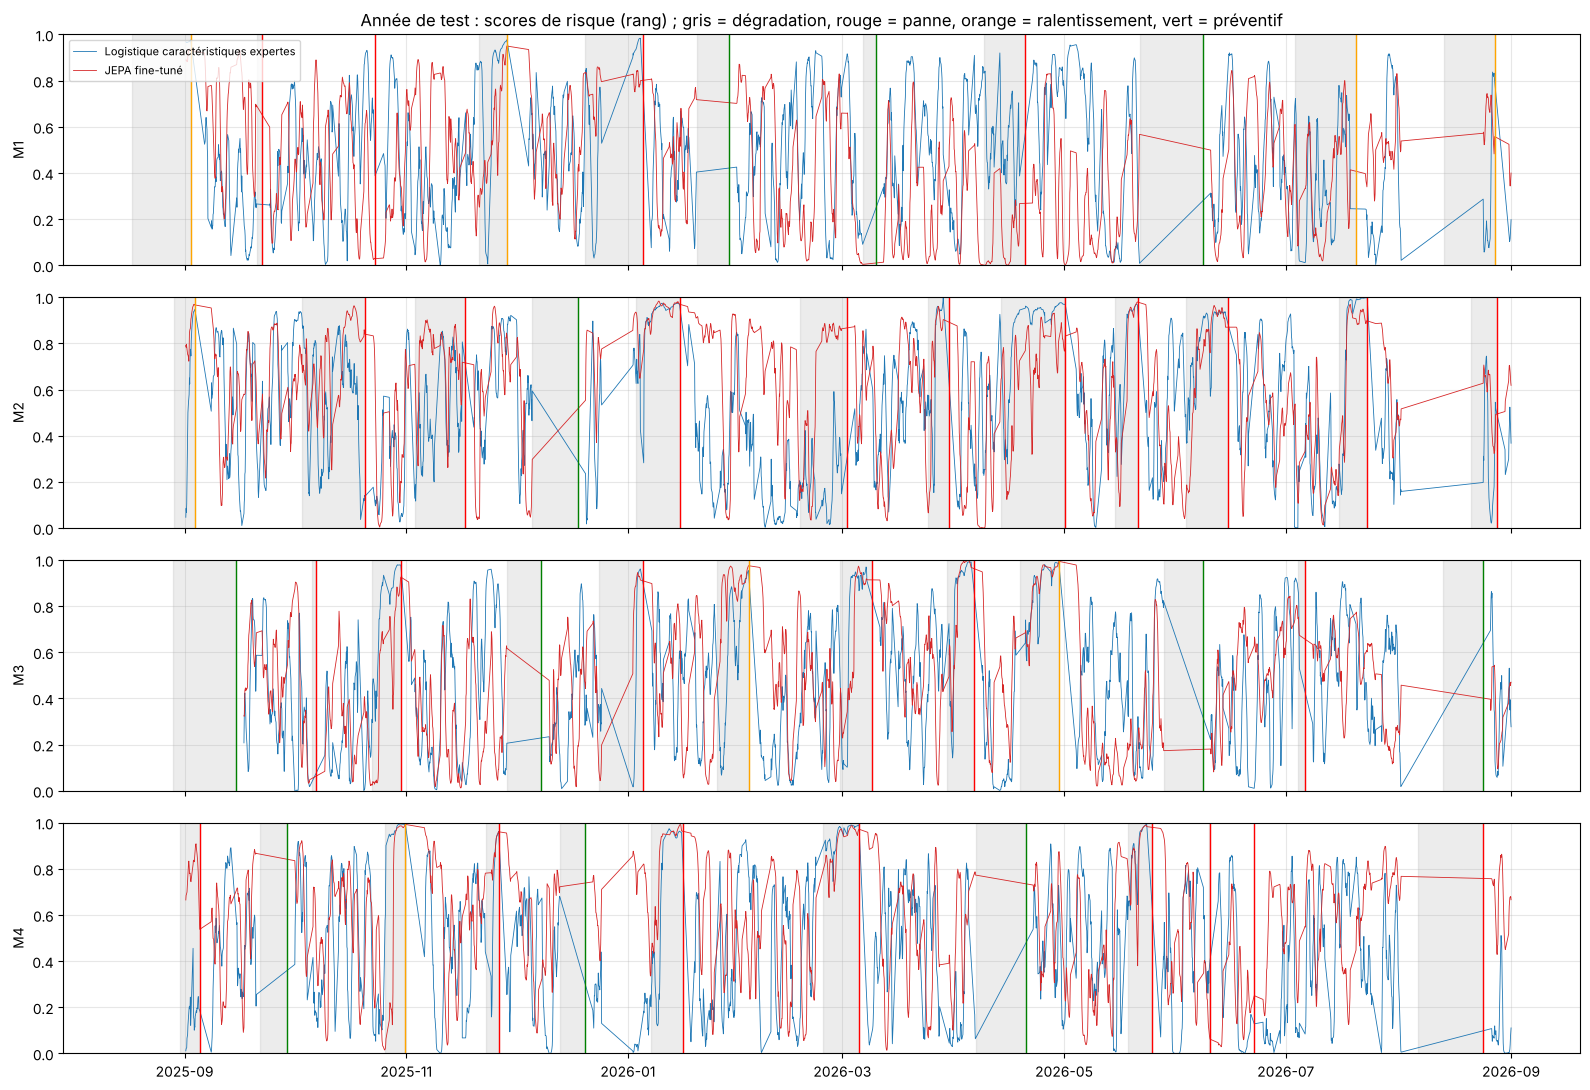

In [21]:
best_base = [k for k in RESULTS.methode if "JEPA" not in k and "aléatoire" not in k and "Autoencodeur" not in k][0]
best_jepa = [k for k in RESULTS.methode if k.startswith("JEPA")][0]
fig, axes = plt.subplots(len(MACH), 1, figsize=(16, 11), sharex=True)
for ax, m in zip(axes, MACH):
    mm = te_m & (E.machine == m).to_numpy()
    for k, c in [(best_base, "C0"), (best_jepa, "C3")]:
        ax.plot(E.time[mm], rank(PRED[k])[mm], lw=0.6, color=c, label=k)
    for _, f in deg[(deg.machine == m) & (deg.evenement >= VAL_END)].iterrows():
        ax.axvspan(f.debut_degradation, f.evenement, color="grey", alpha=0.15)
        ax.axvline(f.evenement, color={"panne": "red", "ralentissement": "orange", "preventif": "green"}[f.issue], lw=1)
    ax.set_ylabel(m); ax.set_ylim(0, 1)
axes[0].legend(loc="upper left", fontsize=8); axes[0].set_title("Année de test : scores de risque (rang) ; gris = dégradation, rouge = panne, orange = ralentissement, vert = préventif")
plt.tight_layout(); plt.savefig(RES / "annee_test.png", dpi=85); plt.show()

## 10. Hypothèses et conclusions

Hypothèses écrites **avant** l'exécution (dans `LISEZMOI_SYNTHETIQUE.md`), confrontées ici aux chiffres sans les réécrire :
- **H1.** Les seuils de niveau et l'EWMA sont proches du hasard (ROC-AUC < 0,60), car le générateur ne déplace pas les niveaux.
- **H2.** La surprise JEPA, sans étiquettes, bat les seuils de niveau.
- **H3.** La sonde sur représentations JEPA bat le même encodeur non pré-entraîné (le pré-entraînement apporte quelque chose).
- **H4.** Le boosting sur caractéristiques expertes (autocorrélations, résidus physiques) est un concurrent sérieux : il peut égaler ou battre JEPA, puisqu'on lui a donné les bonnes caractéristiques.
- **H5.** Les défauts `electrique` restent imprévisibles (ROC-AUC par type ≈ 0,5 pour toutes les méthodes).

In [22]:
R = RESULTS.set_index("methode").roc_auc
def g(k): return R.get(k, np.nan)
print(f"H1 : seuil niveau {g('Seuil niveau (max |z|)'):.3f}, EWMA {g('EWMA 3 j niveaux'):.3f} -> {'confirmée' if max(g('Seuil niveau (max |z|)'), g('EWMA 3 j niveaux')) < 0.60 else 'non confirmée'}")
seuils = max(g('Seuil niveau (max |z|)'), g('EWMA 3 j niveaux'))
print(f"H2 : surprise JEPA {g('JEPA surprise (non supervisé)'):.3f} vs meilleur seuil {seuils:.3f} -> {'confirmée' if g('JEPA surprise (non supervisé)') > seuils + 0.02 else 'non confirmée'} (critère : au moins +0,02)")
print(f"   (complément ajouté après coup : distance à la normale JEPA {g('JEPA distance à la normale (non supervisé)'):.3f})")
d3 = [roc_auc_score(yt, PER_SEED[s_]['JEPA sonde logistique'][te_m]) - roc_auc_score(yt, PER_SEED[s_]['Encodeur aléatoire sonde logistique'][te_m]) for s_ in SEEDS]
print(f"H3 : sonde JEPA - encodeur aléatoire = {np.mean(d3):+.3f} (par graine : {', '.join(f'{x:+.3f}' for x in d3)}) -> {'confirmée' if min(d3) > 0 else 'non confirmée'}")
bj = max(g('JEPA sonde logistique'), g('JEPA fine-tuné'))
print(f"H4 : boosting expert {g('Boosting caractéristiques expertes'):.3f} vs meilleure tête JEPA {bj:.3f} -> {'confirmée' if g('Boosting caractéristiques expertes') >= bj - 0.01 else 'non confirmée (JEPA devant)'}")
d_ft = [roc_auc_score(yt, PER_SEED[s_]['JEPA fine-tuné'][te_m]) - roc_auc_score(yt, PER_SEED[s_]['Encodeur aléatoire fine-tuné'][te_m]) for s_ in SEEDS]
print(f"   (complément : fine-tuning JEPA - aléatoire = {np.mean(d_ft):+.3f}, par graine {', '.join(f'{x:+.3f}' for x in d_ft)})")
print(f"   (complément : boosting experts + JEPA {g('Boosting experts + JEPA'):.3f} vs boosting experts seul {g('Boosting caractéristiques expertes'):.3f})")
print("\nComparaison JEPA / autoencodeur masqué (ajoutée après coup, non pré-enregistrée) :")
for tete in ["sonde logistique", "fine-tuné"]:
    dj = [roc_auc_score(yt, PER_SEED[s_][f'JEPA {tete}'][te_m]) - roc_auc_score(yt, PER_SEED[s_][f'Autoencodeur {tete}'][te_m]) for s_ in SEEDS]
    print(f"   {tete:<17} : JEPA {g(f'JEPA {tete}'):.3f}, autoencodeur {g(f'Autoencodeur {tete}'):.3f} ; JEPA - autoencodeur par graine : {', '.join(f'{x:+.3f}' for x in dj)}")
print(f"   non supervisé     : surprise JEPA {g('JEPA surprise (non supervisé)'):.3f}, erreur de reconstruction {g('Autoencodeur erreur de reconstruction (non supervisé)'):.3f}")
print(f"H5 : ROC-AUC sur les défauts électriques : {PAR_TYPE['electrique'].round(2).to_dict()}")
print(f"\nDurée totale : {(time.time() - t_start) / 60:.0f} min")

H1 : seuil niveau 0.508, EWMA 0.497 -> confirmée
H2 : surprise JEPA 0.508 vs meilleur seuil 0.508 -> non confirmée (critère : au moins +0,02)
   (complément ajouté après coup : distance à la normale JEPA 0.533)
H3 : sonde JEPA - encodeur aléatoire = +0.013 (par graine : +0.004, -0.005, +0.039) -> non confirmée
H4 : boosting expert 0.716 vs meilleure tête JEPA 0.748 -> non confirmée (JEPA devant)
   (complément : fine-tuning JEPA - aléatoire = +0.004, par graine +0.016, -0.036, +0.031)
   (complément : boosting experts + JEPA 0.725 vs boosting experts seul 0.716)

Comparaison JEPA / autoencodeur masqué (ajoutée après coup, non pré-enregistrée) :
   sonde logistique  : JEPA 0.683, autoencodeur 0.714 ; JEPA - autoencodeur par graine : -0.029, -0.050, -0.034
   fine-tuné         : JEPA 0.748, autoencodeur 0.704 ; JEPA - autoencodeur par graine : +0.014, -0.009, +0.102
   non supervisé     : surprise JEPA 0.508, erreur de reconstruction 0.467
H5 : ROC-AUC sur les défauts électriques : {'JEP

## Conclusions (écrites après l'exécution, à relire si on relance avec d'autres paramètres)

1. **Les données remplissent le cahier des charges.** Les seuils de niveau et l'EWMA sont au hasard (ROC-AUC 0,50–0,51) : le niveau des capteurs ne dit rien des pannes à venir.
2. **Le meilleur score est celui du JEPA fine-tuné** : ROC-AUC 0,75 [0,67 ; 0,82] sur l'année de test, 23 événements anticipés sur 36 (77 % hors défauts électriques), 4,6 jours d'avance médiane, 0,4 fausse alerte par machine et par mois (le taux le plus bas). Il devance le boosting sur caractéristiques expertes (0,72), mais les intervalles de confiance se chevauchent largement : 36 événements de test, c'est peu.
3. **Ce score ne vient presque pas du pré-entraînement JEPA.** Le même Transformer fine-tuné depuis des poids aléatoires atteint 0,73 ; par graine, l'écart JEPA − aléatoire vaut +0,016, −0,036 et +0,031 (sonde : +0,004, −0,005, +0,039). H3 n'est pas confirmée. Ce qui marche, c'est surtout l'architecture (Transformer sur des tokens niveau / amplitude / forme) entraînée avec les étiquettes.
4. **JEPA contre autoencodeur masqué (même encodeur, mêmes masques, mêmes lots) : pas de gagnant net.**
   - Avec l'encodeur **gelé** (sonde logistique), qui mesure directement la qualité de la représentation pré-entraînée, l'**autoencodeur est meilleur** : 0,714 contre 0,683, et devant pour chacune des 3 graines (écarts −0,029, −0,050, −0,034 pour JEPA). Il détecte notamment très bien le refroidissement (0,86).
   - **Après fine-tuning**, JEPA est devant : 0,748 contre 0,704 ; mais l'écart vient surtout d'une graine (+0,014, −0,009, +0,102), et l'autoencodeur fine-tuné fait moins bien que des poids aléatoires (0,726). L'initialisation autoencodeur gêne un peu le fine-tuning, l'initialisation JEPA ne l'aide guère.
   - **Sans étiquettes**, les deux échouent : erreur de reconstruction 0,47, surprise JEPA 0,51 ; distance à la normale 0,57 (autoencodeur) et 0,53 (JEPA).
   - Sur ces données, on ne peut donc pas dire que l'objectif JEPA (prédire dans l'espace latent) soit meilleur que la reconstruction.
5. **Les modèles appris voient ce que les caractéristiques expertes ne voient pas** : le refroidissement dégradé (réponse thermique plus lente), 0,68 à 0,86 selon la tête contre 0,43 à 0,48 pour le boosting expert. À l'inverse, le boosting expert est meilleur sur roulement et fuite pneumatique, dont la signature est presque exactement une de ses caractéristiques (autocorrélation).
6. **Les défauts électriques restent imprévisibles** (≈ 0,5 partout), comme prévu.

**Ce que ça veut dire pour le stage.** Sur ces données synthétiques (cas favorable construit exprès), un Transformer fine-tuné sur les capteurs bruts est le plus performant ; le pré-entraînement JEPA n'apporte pas un gain net, ni face à des poids aléatoires ni face à un autoencodeur masqué. Le pré-entraînement a le plus de chances de payer quand les étiquettes sont rares : une prochaine expérience utile serait de ne garder que 10 pannes étiquetées en entraînement (au lieu de 62) et de refaire la comparaison JEPA / autoencodeur / aléatoire.